### shapely 4: Abbildungen und Anwendungen - Übungen

In diesem Notebook bewegst und veränderst du Figuren mit **Kongruenz- und Ähnlichkeitsabbildungen** (Verschieben, Drehen, Spiegeln, Strecken)
und setzt shapely in anderen Gebieten der Mathematik ein: **Flächen unter Funktionsgraphen** (Analysis) und **Flächen schätzen mit Zufallspunkten** (Stochastik).

Die Reihe hat vier Notebooks:

1. Grundlagen: Geometrien erstellen, messen und zeichnen
2. Lagebeziehungen: Lage, Schnittpunkte, Abstände
3. Mengen und Konstruktionen: Schnitt und Vereinigung, Abstandsbereiche, Hüllen, Voronoi-Diagramme
4. **Abbildungen und Anwendungen** (dieses Notebook)

Für die Graphen brauchst du `np.linspace()` aus den numpy-Notebooks, für die Zufallspunkte `random.uniform()` aus dem Notebook zu `random`.
Wie bisher werden Ergebnisse gerundet ausgegeben.

Jeder Abschnitt beginnt mit kurzen Erklärungen und Beispielen. Führe die Beispiele aus und probiere sie ruhig ein wenig aus.
Danach folgen viele kleine Übungen. Wenn etwas vorgegeben ist, steht es schon in der Codezelle.

Unter den Aufgaben kannst du jeweils die Lösung aufklappen. Versuche es aber immer zuerst selbst!
Bei den Aufgaben „Was wird ausgegeben?“ gibt es keine Lösung zum Aufklappen: Dort führst du einfach die Zelle aus und vergleichst.

## 1. Verschieben

#### `translate`

Die Abbildungen stehen im Modul `shapely.affinity`. Sie geben immer eine **neue** Figur zurück.

`translate(g, xoff, yoff)` verschiebt eine Figur um den Vektor (xoff | yoff). Längen, Winkel und Flächen bleiben gleich.

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import translate

d = Polygon([(0, 0), (4, 0), (0, 3)])
d2 = translate(d, 5, 2)
print(shapely.to_wkt(d2, rounding_precision=2))
print(d.area, d2.area)

#### Aufgabe 1.1

Verschiebe das Dreieck A(1|1), B(5|2), C(2|4) um den Vektor (−3|4). Gib das Bild gerundet aus und prüfe, ob Fläche und Umfang gleich geblieben sind.

**Erwartete Ausgabe:**
```
POLYGON ((-2 5, 2 6, -1 8, -2 5))
True True
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import translate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import translate
d = Polygon([(1, 1), (5, 2), (2, 4)])
b = translate(d, -3, 4)
print(shapely.to_wkt(b, rounding_precision=2))
print(d.area == b.area, round(d.length, 9) == round(b.length, 9))
```

</details>

#### Aufgabe 1.2

Ein Spielstein (`stein`) zieht nacheinander um die Vektoren in `zuege`. Gib nach jedem Zug den Schwerpunkt gerundet aus und am Ende, ob der Stein mit seiner Startposition überlappt.

**Erwartete Ausgabe:**
```
POINT (4 1)
POINT (4 4)
POINT (2 3)
False
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import translate

stein = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
zuege = [(3, 0), (0, 3), (-2, -1)]
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import translate

stein = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
zuege = [(3, 0), (0, 3), (-2, -1)]
start = stein
for dx, dy in zuege:
    stein = translate(stein, dx, dy)
    print(shapely.to_wkt(stein.centroid, rounding_precision=2))
print(stein.intersects(start) and not stein.touches(start))
```

</details>

#### Aufgabe 1.3

Ein Parkett besteht aus Kopien eines L-Steins (`stein`), jeweils um (3|0) bzw. (0|3) verschoben (3 × 3 Kopien, also verschoben um (3i|3j) für i, j = 0, 1, 2).
Gib die Fläche der Vereinigung und die Summe der Einzelflächen aus. Sind sie gleich, überlappen sich die Steine nicht.

**Erwartete Ausgabe:**
```
45.0 45.0
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import translate

stein = Polygon([(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import translate

stein = Polygon([(0, 0), (3, 0), (3, 1), (1, 1), (1, 3), (0, 3)])
kopien = []
for i in range(3):
    for j in range(3):
        kopien.append(translate(stein, 3 * i, 3 * j))
summe = 0
for k in kopien:
    summe += k.area
print(shapely.union_all(kopien).area, summe)
```

</details>

#### Aufgabe 1.4

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from shapely import Point
from shapely.affinity import translate

p = Point(2, 3)
q = translate(translate(p, 1, -1), -3, 4)
print(q)
print(p)

## 2. Drehen

#### `rotate`

`rotate(g, winkel, origin=...)` dreht eine Figur um `winkel` Grad **gegen den Uhrzeigersinn** (negative Winkel: im Uhrzeigersinn).
Das **Drehzentrum** gibt man mit `origin` an:

- `origin=(x, y)` oder ein `Point`: um diesen Punkt,
- `origin='centroid'`: um den Schwerpunkt der Figur,
- ohne Angabe: um die Mitte des umgebenden Rechtecks. Deshalb gibt man `origin` am besten **immer** an.

Bei einer Drehung um (0|0) um 90° wird aus (x|y) der Punkt (−y|x).

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import rotate

d = Polygon([(1, 0), (4, 0), (1, 2)])
print(shapely.to_wkt(rotate(d, 90, origin=(0, 0)), rounding_precision=2))
print(shapely.to_wkt(rotate(d, 180, origin=(0, 0)), rounding_precision=2))
print(shapely.to_wkt(rotate(d, 45, origin='centroid'), rounding_precision=2))

#### Sind zwei Figuren gleich?

Nach einer Drehung haben die Koordinaten oft winzige Rundungsfehler (z. B. `2.9999999999999996`), und die Ecken können in anderer Reihenfolge stehen.
Ob zwei Figuren **gleich** sind, prüft man deshalb über die Fläche ihrer symmetrischen Differenz: Ist sie (fast) 0, sind sie gleich.

In [ ]:
from shapely import Polygon
from shapely.affinity import rotate

def gleich(a, b):
    return (a ^ b).area < 1e-9

q = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
print(gleich(q, rotate(q, 90, origin='centroid')))
print(gleich(q, rotate(q, 45, origin='centroid')))

#### Aufgabe 2.1

Drehe den Punkt P(3|1) um (0|0) um 90°, 180° und 270° und gib die Bildpunkte gerundet aus. Prüfe die Regel (x|y) → (−y|x) für 90°.

**Erwartete Ausgabe:**
```
90 POINT (-1 3)
180 POINT (-3 -1)
270 POINT (1 -3)
-1.0 3.0
```

In [ ]:
import shapely
from shapely import Point
from shapely.affinity import rotate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Point
from shapely.affinity import rotate
p = Point(3, 1)
for w in [90, 180, 270]:
    print(w, shapely.to_wkt(rotate(p, w, origin=(0, 0)), rounding_precision=2))
print(-p.y, p.x)
```

</details>

#### Aufgabe 2.2

Drehe das Rechteck von (2|1) bis (6|3) um seine Ecke (2|1) um 30° und gib die Eckpunkte des Bildes gerundet aus. Prüfe, ob die Fläche gleich bleibt (gerundet auf 9 Stellen).

**Erwartete Ausgabe:**
```
POLYGON ((2 1, 5.46 3, 4.46 4.73, 1 2.73, 2 1))
True
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import rotate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import rotate
r = Polygon([(2, 1), (6, 1), (6, 3), (2, 3)])
b = rotate(r, 30, origin=(2, 1))
print(shapely.to_wkt(b, rounding_precision=2))
print(round(b.area, 9) == r.area)
```

</details>

#### Aufgabe 2.3

Ein regelmäßiges n-Eck ist **drehsymmetrisch**: Dreht man es um 360°/n um seinen Mittelpunkt, ist es wieder dasselbe. Prüfe für das Sechseck `s` die Drehwinkel 30°, 60°, 90° und 120°
mit der Funktion `gleich()`.

**Erwartete Ausgabe:**
```
30 False
60 True
90 False
120 True
```

In [ ]:
import math
from shapely import Polygon
from shapely.affinity import rotate

def gleich(a, b):
    return (a ^ b).area < 1e-9

punkte = []
for k in range(6):
    punkte.append((math.cos(2 * math.pi * k / 6), math.sin(2 * math.pi * k / 6)))
s = Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import math
from shapely import Polygon
from shapely.affinity import rotate

def gleich(a, b):
    return (a ^ b).area < 1e-9

punkte = []
for k in range(6):
    punkte.append((math.cos(2 * math.pi * k / 6), math.sin(2 * math.pi * k / 6)))
s = Polygon(punkte)
for w in [30, 60, 90, 120]:
    print(w, gleich(s, rotate(s, w, origin=(0, 0))))
```

</details>

#### Aufgabe 2.4

Erzeuge eine Windmühle: Drehe das Rechteck-Flügelblatt `blatt` um (0|0) um 0°, 90°, 180° und 270° und vereinige die vier Blätter. Gib die Gesamtfläche aus und zeichne die Windmühle
(Füllung `'lightblue'`, Rand `'C0'`, ohne Eckpunkte). Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**
```
14.0
```

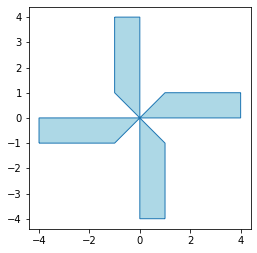

In [ ]:
import matplotlib.pyplot as plt
import shapely
from shapely import Polygon
from shapely.affinity import rotate
from shapely.plotting import plot_polygon

blatt = Polygon([(0, 0), (4, 0), (4, 1), (1, 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import shapely
from shapely import Polygon
from shapely.affinity import rotate
from shapely.plotting import plot_polygon

blatt = Polygon([(0, 0), (4, 0), (4, 1), (1, 1)])
blaetter = []
for w in [0, 90, 180, 270]:
    blaetter.append(rotate(blatt, w, origin=(0, 0)))
muehle = shapely.union_all(blaetter)
print(round(muehle.area, 6))
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(muehle, ax=ax, facecolor='lightblue', edgecolor='C0', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 2.5

Ein Uhrzeiger (Strecke von (0|0) nach (0|5)) dreht sich jede Minute um 6° **im Uhrzeigersinn**. Gib die Spitze des Zeigers nach 15, 20 und 45 Minuten gerundet aus.

**Erwartete Ausgabe:**
```
15 POINT (5 0)
20 POINT (4.33 -2.5)
45 POINT (-5 0)
```

In [ ]:
import shapely
from shapely import LineString, Point
from shapely.affinity import rotate
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString, Point
from shapely.affinity import rotate
zeiger = LineString([(0, 0), (0, 5)])
for minuten in [15, 20, 45]:
    z = rotate(zeiger, -6 * minuten, origin=(0, 0))
    print(minuten, shapely.to_wkt(Point(z.coords[1]), rounding_precision=2))
```

</details>

#### Aufgabe 2.6

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
import shapely
from shapely import Point
from shapely.affinity import rotate

p = Point(2, 0)
print(shapely.to_wkt(rotate(p, 90, origin=(0, 0)), rounding_precision=2))
print(shapely.to_wkt(rotate(p, 90, origin=(2, 0)), rounding_precision=2))
print(shapely.to_wkt(rotate(p, -90, origin=(1, 0)), rounding_precision=2))

## 3. Spiegeln

#### Spiegeln mit `scale`

`scale(g, xfact, yfact, origin=...)` multipliziert die Abstände zum Punkt `origin` in x-Richtung mit `xfact` und in y-Richtung mit `yfact`. Mit Faktoren −1 entstehen Spiegelungen:

| Aufruf | Spiegelung |
|---|---|
| `scale(g, -1, 1, origin=(0, 0))` | an der y-Achse |
| `scale(g, 1, -1, origin=(0, 0))` | an der x-Achse |
| `scale(g, -1, 1, origin=(a, 0))` | an der senkrechten Geraden x = a |
| `scale(g, -1, -1, origin=(a, b))` | **Punktspiegelung** am Punkt (a\|b) (dasselbe wie Drehung um 180°) |

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import scale

d = Polygon([(1, 1), (4, 1), (1, 3)])
print(shapely.to_wkt(scale(d, -1, 1, origin=(0, 0)), rounding_precision=2))
print(shapely.to_wkt(scale(d, 1, -1, origin=(0, 0)), rounding_precision=2))
print(shapely.to_wkt(scale(d, -1, 1, origin=(5, 0)), rounding_precision=2))
print(shapely.to_wkt(scale(d, -1, -1, origin=(0, 0)), rounding_precision=2))

#### Spiegeln an einer schrägen Achse

An einer Geraden durch den Punkt Z mit dem Steigungswinkel α spiegelt man so: erst um Z um −α drehen (die Achse wird waagrecht), dann an der waagrechten Geraden durch Z spiegeln,
dann wieder um α zurückdrehen. Die Winkelhalbierende y = x hat α = 45°: Dort wird aus (x|y) der Punkt (y|x).

In [ ]:
import shapely
from shapely import Point
from shapely.affinity import rotate, scale

def spiegeln(g, z, alpha):
    g = rotate(g, -alpha, origin=z)
    g = scale(g, 1, -1, origin=z)
    return rotate(g, alpha, origin=z)

print(shapely.to_wkt(spiegeln(Point(3, 1), (0, 0), 45), rounding_precision=2))

#### Aufgabe 3.1

Spiegle das Viereck A(1|0), B(4|1), C(3|3), D(1|2) an der Geraden x = 5 und gib das Bild in Normalform gerundet aus.

**Erwartete Ausgabe:**
```
POLYGON ((6 1, 7 3, 9 2, 9 0, 6 1))
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import scale
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import scale
v = Polygon([(1, 0), (4, 1), (3, 3), (1, 2)])
print(shapely.to_wkt(shapely.normalize(scale(v, -1, 1, origin=(5, 0))), rounding_precision=2))
```

</details>

#### Aufgabe 3.2

Eine Figur ist **achsensymmetrisch** zur y-Achse, wenn sie mit ihrem Spiegelbild übereinstimmt. Prüfe das mit der Funktion `gleich()` für alle Figuren in `figuren`.

**Erwartete Ausgabe:**
```
Haus True
Fahne False
Raute True
Trapez False
```

In [ ]:
from shapely import Polygon
from shapely.affinity import scale

def gleich(a, b):
    return (a ^ b).area < 1e-9

figuren = {'Haus': Polygon([(-2, 0), (2, 0), (2, 3), (0, 5), (-2, 3)]), 'Fahne': Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)]),
           'Raute': Polygon([(0, -2), (1, 0), (0, 2), (-1, 0)]), 'Trapez': Polygon([(-3, 0), (3, 0), (1, 2), (-2, 2)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon
from shapely.affinity import scale

def gleich(a, b):
    return (a ^ b).area < 1e-9

figuren = {'Haus': Polygon([(-2, 0), (2, 0), (2, 3), (0, 5), (-2, 3)]), 'Fahne': Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)]),
           'Raute': Polygon([(0, -2), (1, 0), (0, 2), (-1, 0)]), 'Trapez': Polygon([(-3, 0), (3, 0), (1, 2), (-2, 2)])}
for name, f in figuren.items():
    print(name, gleich(f, scale(f, -1, 1, origin=(0, 0))))
```

</details>

#### Aufgabe 3.3

Prüfe für dieselben Figuren, ob sie **punktsymmetrisch** zu ihrem Schwerpunkt sind (Punktspiegelung am `centroid`).

**Erwartete Ausgabe:**
```
Haus False
Fahne False
Raute True
Parallelogramm True
```

In [ ]:
from shapely import Polygon
from shapely.affinity import scale

def gleich(a, b):
    return (a ^ b).area < 1e-9

figuren = {'Haus': Polygon([(-2, 0), (2, 0), (2, 3), (0, 5), (-2, 3)]), 'Fahne': Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)]),
           'Raute': Polygon([(0, -2), (1, 0), (0, 2), (-1, 0)]), 'Parallelogramm': Polygon([(0, 0), (4, 0), (5, 2), (1, 2)])}
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon
from shapely.affinity import scale

def gleich(a, b):
    return (a ^ b).area < 1e-9

figuren = {'Haus': Polygon([(-2, 0), (2, 0), (2, 3), (0, 5), (-2, 3)]), 'Fahne': Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)]),
           'Raute': Polygon([(0, -2), (1, 0), (0, 2), (-1, 0)]), 'Parallelogramm': Polygon([(0, 0), (4, 0), (5, 2), (1, 2)])}
for name, f in figuren.items():
    print(name, gleich(f, scale(f, -1, -1, origin=f.centroid)))
```

</details>

#### Aufgabe 3.4

Spiegle das Dreieck A(1|0), B(5|1), C(2|3) mit der Funktion `spiegeln()` aus dem Beispiel an der Winkelhalbierenden y = x und gib das Bild in Normalform gerundet aus.
Vergleiche mit dem Dreieck, bei dem in jedem Eckpunkt x und y vertauscht sind.

**Erwartete Ausgabe:**
```
POLYGON ((0 1, 1 5, 3 2, 0 1))
POLYGON ((0 1, 1 5, 3 2, 0 1))
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale

def spiegeln(g, z, alpha):
    g = rotate(g, -alpha, origin=z)
    g = scale(g, 1, -1, origin=z)
    return rotate(g, alpha, origin=z)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale

def spiegeln(g, z, alpha):
    g = rotate(g, -alpha, origin=z)
    g = scale(g, 1, -1, origin=z)
    return rotate(g, alpha, origin=z)

d = Polygon([(1, 0), (5, 1), (2, 3)])
print(shapely.to_wkt(shapely.normalize(spiegeln(d, (0, 0), 45)), rounding_precision=2))
print(shapely.to_wkt(shapely.normalize(Polygon([(0, 1), (1, 5), (3, 2)])), rounding_precision=2))
```

</details>

#### Aufgabe 3.5

Zwei Spiegelungen an parallelen Geraden ergeben eine Verschiebung. Spiegle das Dreieck `d` erst an x = 2, dann an x = 5. Gib das Bild in Normalform aus und das um (6|0) verschobene Dreieck
in Normalform.

**Erwartete Ausgabe:**
```
POLYGON ((6 0, 6 2, 7 0, 6 0))
POLYGON ((6 0, 6 2, 7 0, 6 0))
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import scale, translate

d = Polygon([(0, 0), (1, 0), (0, 2)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import scale, translate

d = Polygon([(0, 0), (1, 0), (0, 2)])
b = scale(scale(d, -1, 1, origin=(2, 0)), -1, 1, origin=(5, 0))
print(shapely.to_wkt(shapely.normalize(b), rounding_precision=2))
print(shapely.to_wkt(shapely.normalize(translate(d, 6, 0)), rounding_precision=2))
```

</details>

#### Aufgabe 3.6

Zeichne die Fahne `f`, ihr Spiegelbild an der Geraden x = 4 (`scale`, Füllung `'orange'`) und die Spiegelachse (schwarz, gestrichelt mit `linestyle='--'`, von (4|−1) nach (4|4),
ohne Eckpunkte). Die Fahne selbst: Füllung `'C0'`. Beide mit `alpha=0.6`, ohne Eckpunkte. Achsen gleich skaliert, Bildgröße 4 × 3.

**Erwartete Ausgabe:**

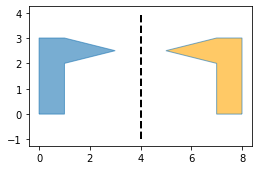

In [ ]:
import matplotlib.pyplot as plt
from shapely import LineString, Polygon
from shapely.affinity import scale
from shapely.plotting import plot_line, plot_polygon

f = Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import LineString, Polygon
from shapely.affinity import scale
from shapely.plotting import plot_line, plot_polygon

f = Polygon([(0, 0), (1, 0), (1, 2), (3, 2.5), (1, 3), (0, 3)])
fig, ax = plt.subplots(figsize=(4, 3))
plot_polygon(f, ax=ax, facecolor='C0', alpha=0.6, add_points=False)
plot_polygon(scale(f, -1, 1, origin=(4, 0)), ax=ax, facecolor='orange', alpha=0.6, add_points=False)
plot_line(LineString([(4, -1), (4, 4)]), ax=ax, color='black', linestyle='--', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 3.7

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from shapely import Point
from shapely.affinity import scale

p = Point(3, 2)
print(scale(p, -1, 1, origin=(0, 0)))
print(scale(p, 1, -1, origin=(0, 1)))
print(scale(p, -1, -1, origin=(1, 1)))

## 4. Zentrische Streckung

#### Strecken mit dem Faktor k

`scale(g, k, k, origin=Z)` ist die **zentrische Streckung** mit Zentrum Z und Streckfaktor k: Jeder Punkt wird auf der Geraden durch Z auf das k-Fache seines Abstandes gebracht.

- Längen werden mit **|k|** multipliziert, Flächen mit **k²**, Winkel bleiben gleich (das Bild ist **ähnlich**).
- Bei negativem k liegt das Bild auf der anderen Seite von Z.
- Mit verschiedenen Faktoren (`scale(g, 2, 1)`) wird die Figur nur in einer Richtung gestreckt; dann ist sie nicht mehr ähnlich.

In [ ]:
from shapely import Polygon
from shapely.affinity import scale

d = Polygon([(0, 0), (4, 0), (0, 3)])
for k in [2, 0.5, -1.5]:
    b = scale(d, k, k, origin=(0, 0))
    print(k, b.length / d.length, b.area / d.area)
print(scale(d, 2, 1, origin=(0, 0)).area / d.area)

#### Aufgabe 4.1

Strecke das Dreieck A(1|1), B(3|1), C(2|3) mit dem Zentrum Z(0|0) und k = 3. Gib das Bild gerundet aus und die Verhältnisse von Umfang und Fläche (2 Stellen).

**Erwartete Ausgabe:**
```
POLYGON ((3 3, 9 3, 6 9, 3 3))
3.0 9.0
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import scale
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import scale
d = Polygon([(1, 1), (3, 1), (2, 3)])
b = scale(d, 3, 3, origin=(0, 0))
print(shapely.to_wkt(b, rounding_precision=2))
print(round(b.length / d.length, 2), round(b.area / d.area, 2))
```

</details>

#### Aufgabe 4.2

Ein Foto (Rechteck 10 × 15 cm) soll so vergrößert werden, dass seine Fläche 600 cm² beträgt. Berechne den Streckfaktor k = √(600 / Fläche), strecke das Rechteck mit `scale` um die Ecke (0|0)
und gib k (3 Stellen), die neue Fläche (2 Stellen) und die neuen Seitenlängen (`bounds`, 2 Stellen) aus.

**Erwartete Ausgabe:**
```
2.0 600.0
20.0 30.0
```

In [ ]:
from shapely import Polygon
from shapely.affinity import scale

foto = Polygon([(0, 0), (10, 0), (10, 15), (0, 15)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon
from shapely.affinity import scale

foto = Polygon([(0, 0), (10, 0), (10, 15), (0, 15)])
k = (600 / foto.area) ** 0.5
b = scale(foto, k, k, origin=(0, 0))
xmin, ymin, xmax, ymax = b.bounds
print(round(k, 3), round(b.area, 2))
print(round(xmax - xmin, 2), round(ymax - ymin, 2))
```

</details>

#### Aufgabe 4.3

Wo liegt das Streckzentrum? Das Dreieck `b` ist das Bild von `d` bei einer zentrischen Streckung. Die Geraden durch einander entsprechende Ecken schneiden sich im Zentrum.
Erzeuge zwei solche Geraden als lange Strecken (über die Ecken hinaus verlängert mit `scale(strecke, 20, 20, origin='center')`) und gib ihren Schnittpunkt gerundet aus.

**Erwartete Ausgabe:**
```
POINT (-1 3)
```

In [ ]:
import shapely
from shapely import LineString, Polygon
from shapely.affinity import scale

d = Polygon([(2, 1), (4, 1), (3, 3)])
b = Polygon([(5, -1), (9, -1), (7, 3)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import LineString, Polygon
from shapely.affinity import scale

d = Polygon([(2, 1), (4, 1), (3, 3)])
b = Polygon([(5, -1), (9, -1), (7, 3)])
e_d = list(d.exterior.coords)
e_b = list(b.exterior.coords)
g1 = scale(LineString([e_d[0], e_b[0]]), 20, 20, origin='center')
g2 = scale(LineString([e_d[1], e_b[1]]), 20, 20, origin='center')
print(shapely.to_wkt(g1 & g2, rounding_precision=2))
```

</details>

#### Aufgabe 4.4

Erzeuge eine „Matroschka“: Das Quadrat `q` wird viermal hintereinander mit k = 0.7 um seinen Schwerpunkt gestreckt. Gib nach jedem Schritt die Fläche (3 Stellen) aus und
zeichne alle fünf Quadrate ohne Füllung (`facecolor='none'`, Rand `'C0'`, ohne Eckpunkte). Achsen gleich skaliert, Bildgröße 3 × 3.

**Erwartete Ausgabe:**
```
49.0
24.01
11.765
5.765
```

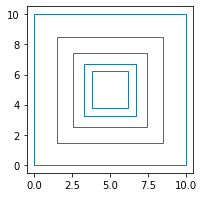

In [ ]:
import matplotlib.pyplot as plt
from shapely import Polygon
from shapely.affinity import scale
from shapely.plotting import plot_polygon

q = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
from shapely import Polygon
from shapely.affinity import scale
from shapely.plotting import plot_polygon

q = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
fig, ax = plt.subplots(figsize=(3, 3))
plot_polygon(q, ax=ax, facecolor='none', edgecolor='C0', add_points=False)
for i in range(4):
    q = scale(q, 0.7, 0.7, origin='centroid')
    print(round(q.area, 3))
    plot_polygon(q, ax=ax, facecolor='none', edgecolor='C0', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 4.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from shapely import Polygon
from shapely.affinity import scale

q = Polygon([(0, 0), (2, 0), (2, 2), (0, 2)])
print(scale(q, 3, 3, origin=(0, 0)).area)
print(scale(q, -1, -1, origin=(0, 0)).area)
print(scale(q, 0.5, 0.5, origin=(0, 0)).bounds)

## 5. Flächen unter Funktionsgraphen

#### Der Graph als Vieleck

Die Fläche zwischen dem Graphen einer Funktion f (mit f(x) ≥ 0) und der x-Achse über [a; b] kann man durch ein **Vieleck** annähern:
Man nimmt viele Punkte (x | f(x)) des Graphen und schließt sie über (b|0) und (a|0) zur x-Achse hin ab. Je mehr Punkte, desto genauer.
Den genauen Wert liefert das **Integral**. Für f(x) = x² über [0; 3] ist es 3³/3 = 9.

In [ ]:
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)

def f(x):
    return x ** 2

for n in [4, 10, 100, 1000]:
    print(n, round(flaeche_unter(f, 0, 3, n).area, 6))

`float(x)` macht aus einer numpy-Zahl eine gewöhnliche Python-Kommazahl. So enthält die Punkteliste nur gewöhnliche Zahlen.

In [ ]:
import numpy as np

x = np.linspace(0, 1, 3)[1]
print(type(x).__name__, type(float(x)).__name__)

#### Fläche zwischen zwei Graphen

Für die Fläche zwischen zwei Graphen f (oben) und g (unten) über [a; b] läuft man auf f von links nach rechts und auf g von rechts nach links zurück.
Die Schnittpunkte zweier Graphen findet man, indem man beide als Streckenzug darstellt und schneidet.

In [ ]:
import numpy as np
import shapely
from shapely import LineString, Polygon

xs = np.linspace(0, 1, 201)
oben = []
unten = []
for x in xs:
    oben.append((float(x), float(x)))
    unten.append((float(x), float(x ** 2)))
unten.reverse()
print(round(Polygon(oben + unten).area, 6), round(1 / 6, 6))
xs = np.linspace(-1, 2, 301)
kurve_f = []
kurve_g = []
for x in xs:
    kurve_f.append((float(x), float(x)))
    kurve_g.append((float(x), float(x ** 2)))
print(shapely.to_wkt(shapely.normalize(LineString(kurve_f) & LineString(kurve_g)), rounding_precision=2))

`liste.reverse()` dreht die Reihenfolge einer Liste um (die Liste selbst wird verändert). `oben + unten` hängt zwei Listen aneinander.

In [ ]:
a = [1, 2, 3]
a.reverse()
print(a, a + [9])

#### Aufgabe 5.1

Berechne mit `flaeche_unter()` die Fläche unter f(x) = 4 − x² über [−2; 2] mit n = 10, 100 und 1000 (6 Stellen). Der genaue Wert ist 32/3; gib ihn zum Vergleich aus.

**Erwartete Ausgabe:**
```
10 10.534979
100 10.665578
1000 10.666656
10.666667
```

In [ ]:
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)


def f(x):
    return 4 - x ** 2

for n in [10, 100, 1000]:
    print(n, round(flaeche_unter(f, -2, 2, n).area, 6))
print(round(32 / 3, 6))
```

</details>

#### Aufgabe 5.2

Für eine **lineare** Funktion ist schon das Vieleck mit n = 2 genau (ein Trapez). Prüfe das für f(x) = 0.5x + 1 über [0; 4]: Gib die Fläche für n = 2 und den Wert der Trapezformel aus.

**Erwartete Ausgabe:**
```
8.0
8.0
```

In [ ]:
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)


def f(x):
    return 0.5 * x + 1

print(flaeche_unter(f, 0, 4, 2).area)
print((f(0) + f(4)) / 2 * 4)
```

</details>

#### Aufgabe 5.3

Wie groß muss n mindestens sein, damit die Fläche unter f(x) = √x über [0; 4] auf 2 Nachkommastellen mit dem genauen Wert 16/3 übereinstimmt? Probiere n = 2, 3, 4, … und gib das
erste passende n und die Fläche (2 Stellen) aus.

**Erwartete Ausgabe:**
```
35 5.33
```

In [ ]:
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from shapely import Polygon

def flaeche_unter(f, a, b, n):
    punkte = [(a, 0)]
    for x in np.linspace(a, b, n):
        punkte.append((float(x), float(f(x))))
    punkte.append((b, 0))
    return Polygon(punkte)


def f(x):
    return x ** 0.5

n = 2
while round(flaeche_unter(f, 0, 4, n).area, 2) != round(16 / 3, 2):
    n += 1
print(n, round(flaeche_unter(f, 0, 4, n).area, 2))
```

</details>

#### Aufgabe 5.4

Bestimme die Fläche zwischen f(x) = x + 2 (oben) und g(x) = x² (unten) über [−1; 2] mit 301 Punkten (6 Stellen). Der genaue Wert ist 4.5.

**Erwartete Ausgabe:**
```
4.49995
```

In [ ]:
import numpy as np
from shapely import Polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from shapely import Polygon
oben = []
unten = []
for x in np.linspace(-1, 2, 301):
    oben.append((float(x), float(x + 2)))
    unten.append((float(x), float(x ** 2)))
unten.reverse()
print(round(Polygon(oben + unten).area, 6))
```

</details>

#### Aufgabe 5.5

Bestimme die Schnittpunkte der Graphen von f(x) = x² − 2x und g(x) = −x + 2 im Bereich [−3; 4] mit Streckenzügen aus 701 Punkten. Gib sie als sortierte Liste gerundeter Tupel
(2 Stellen) aus. (Genau: x² − x − 2 = 0, also x = −1 und x = 2.)

**Erwartete Ausgabe:**
```
[(-1.0, 3.0), (2.0, 0.0)]
```

In [ ]:
import numpy as np
from shapely import LineString
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import numpy as np
from shapely import LineString
kf = []
kg = []
for x in np.linspace(-3, 4, 701):
    kf.append((float(x), float(x ** 2 - 2 * x)))
    kg.append((float(x), float(-x + 2)))
s = LineString(kf) & LineString(kg)
punkte = []
for p in s.geoms:
    punkte.append((round(p.x, 2), round(p.y, 2)))
print(sorted(punkte))
```

</details>

#### Aufgabe 5.6

Zeichne die Fläche zwischen f(x) = x + 2 und g(x) = x² über [−1; 2] (Füllung `'lightgreen'`, ohne Rand: `edgecolor='none'`, ohne Eckpunkte) und beide Graphen über [−1.5; 2.5]
als Linien (f: `'C0'`, g: `'C1'`, ohne Eckpunkte). Titel: die Fläche auf 3 Stellen, z. B. `A = 4.5`. Bildgröße 4 × 3.

**Erwartete Ausgabe:**

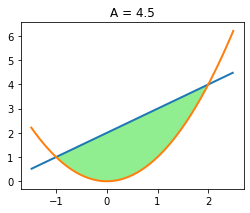

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from shapely import LineString, Polygon
from shapely.plotting import plot_line, plot_polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import numpy as np
from shapely import LineString, Polygon
from shapely.plotting import plot_line, plot_polygon
oben = []
unten = []
for x in np.linspace(-1, 2, 301):
    oben.append((float(x), float(x + 2)))
    unten.append((float(x), float(x ** 2)))
unten.reverse()
flaeche = Polygon(oben + unten)
kf = []
kg = []
for x in np.linspace(-1.5, 2.5, 201):
    kf.append((float(x), float(x + 2)))
    kg.append((float(x), float(x ** 2)))
fig, ax = plt.subplots(figsize=(4, 3))
plot_polygon(flaeche, ax=ax, facecolor='lightgreen', edgecolor='none', add_points=False)
plot_line(LineString(kf), ax=ax, color='C0', add_points=False)
plot_line(LineString(kg), ax=ax, color='C1', add_points=False)
ax.set_title(f'A = {round(flaeche.area, 3)}')
plt.show()
```

</details>

## 6. Flächen schätzen mit Zufallspunkten

#### Monte-Carlo-Methode

Man wirft zufällig viele Punkte in ein Rechteck, dessen Fläche man kennt, und zählt, wie viele davon in der Figur landen. Der **Anteil der Treffer** ist ungefähr
der Anteil der Figur am Rechteck. So kann man Flächen schätzen, ohne eine Formel zu kennen. Je mehr Punkte, desto genauer (meistens).

Mit `random.seed()` erhält man bei jedem Lauf dieselben Zufallszahlen.

In [ ]:
import random
from shapely import Point, Polygon

random.seed(1)
dreieck = Polygon([(0, 0), (4, 0), (0, 3)])
treffer = 0
n = 2000
for i in range(n):
    p = Point(random.uniform(0, 4), random.uniform(0, 3))
    if dreieck.contains(p):
        treffer += 1
print(treffer / n * 12, dreieck.area)

#### Aufgabe 6.1

Schätze π: Wirf mit `random.seed(7)` nacheinander n Punkte in das Quadrat von (−1|−1) bis (1|1) (erst x, dann y mit `random.uniform(-1, 1)`) und zähle die Treffer im Einheitskreis
(x² + y² ≤ 1). Die Kreisfläche π ist ungefähr Trefferanteil · 4. Gib die Schätzung für n = 100, 1000 und 10000 aus (4 Stellen); setze vor jedem n den Seed neu.

**Erwartete Ausgabe:**
```
100 3.2
1000 3.032
10000 3.1404
```

In [ ]:
import random
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
for n in [100, 1000, 10000]:
    random.seed(7)
    treffer = 0
    for i in range(n):
        x = random.uniform(-1, 1)
        y = random.uniform(-1, 1)
        if x * x + y * y <= 1:
            treffer += 1
    print(n, round(treffer / n * 4, 4))
```

</details>

#### Aufgabe 6.2

Schätze die Fläche des Sterns `stern` mit 5000 Zufallspunkten im umgebenden Rechteck (`bounds`, `random.seed(3)`, erst x, dann y). Gib die Schätzung (2 Stellen) und die
genaue Fläche aus.

**Erwartete Ausgabe:**
```
4.06
4.0
```

In [ ]:
import random
from shapely import Point, Polygon

stern = Polygon([(0, 2), (1.5, 1.5), (2, 0), (2.5, 1.5), (4, 2), (2.5, 2.5), (2, 4), (1.5, 2.5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
from shapely import Point, Polygon

stern = Polygon([(0, 2), (1.5, 1.5), (2, 0), (2.5, 1.5), (4, 2), (2.5, 2.5), (2, 4), (1.5, 2.5)])
random.seed(3)
xmin, ymin, xmax, ymax = stern.bounds
treffer = 0
n = 5000
for i in range(n):
    p = Point(random.uniform(xmin, xmax), random.uniform(ymin, ymax))
    if stern.contains(p):
        treffer += 1
print(round(treffer / n * (xmax - xmin) * (ymax - ymin), 2))
print(stern.area)
```

</details>

#### Aufgabe 6.3

Wie groß ist die Wahrscheinlichkeit, dass ein zufälliger Punkt im Quadrat von (0|0) bis (10|10) näher an der Mitte (5|5) liegt als am Rand des Quadrats? Schätze sie mit 4000 Punkten
(`random.seed(11)`, erst x, dann y). Der Abstand zum Rand ist `p.distance(quadrat.exterior)`. Gib den geschätzten Anteil (3 Stellen) aus.

**Erwartete Ausgabe:**
```
0.228
```

In [ ]:
import random
from shapely import Point, Polygon

quadrat = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
mitte = Point(5, 5)
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
from shapely import Point, Polygon

quadrat = Polygon([(0, 0), (10, 0), (10, 10), (0, 10)])
mitte = Point(5, 5)
random.seed(11)
treffer = 0
n = 4000
for i in range(n):
    p = Point(random.uniform(0, 10), random.uniform(0, 10))
    if p.distance(mitte) < p.distance(quadrat.exterior):
        treffer += 1
print(round(treffer / n, 3))
```

</details>

#### Aufgabe 6.4

Zeichne die 300 Zufallspunkte aus `random.seed(5)` im Quadrat von (0|0) bis (4|4) (erst x, dann y): Punkte im Kreis um (2|2) mit Radius 2 (`buffer(2, quad_segs=64)`) grün, die
anderen grau (`'gray'`), und den Kreis ohne Füllung (Rand `'black'`, ohne Eckpunkte). Titel: die Schätzung für π (Trefferanteil · 4, 3 Stellen). Achsen gleich skaliert, Bildgröße 3 × 3.

**Erwartete Ausgabe:**

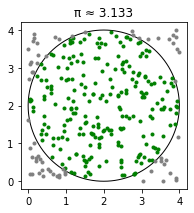

In [ ]:
import random
import matplotlib.pyplot as plt
from shapely import MultiPoint, Point
from shapely.plotting import plot_points, plot_polygon
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import random
import matplotlib.pyplot as plt
from shapely import MultiPoint, Point
from shapely.plotting import plot_points, plot_polygon
random.seed(5)
kreis = Point(2, 2).buffer(2, quad_segs=64)
drin = []
draussen = []
for i in range(300):
    x = random.uniform(0, 4)
    y = random.uniform(0, 4)
    if kreis.contains(Point(x, y)):
        drin.append((x, y))
    else:
        draussen.append((x, y))
fig, ax = plt.subplots(figsize=(3, 3))
plot_points(MultiPoint(drin), ax=ax, color='green', markersize=3)
plot_points(MultiPoint(draussen), ax=ax, color='gray', markersize=3)
plot_polygon(kreis, ax=ax, facecolor='none', edgecolor='black', add_points=False)
ax.set_title(f'π ≈ {round(len(drin) / 300 * 4, 3)}')
ax.set_aspect('equal')
plt.show()
```

</details>

## 7. Gemischte Übungen

#### Aufgabe 7.1

In einem Spiel ist ein Auto ein Rechteck (`auto`), das sich um seinen Schwerpunkt drehen kann. Prüfe für die Drehwinkel 0°, 30°, 60° und 90°, ob das gedrehte Auto die Wand (`wand`)
berührt oder überlappt (`intersects`).

**Erwartete Ausgabe:**
```
0 False
30 True
60 False
90 False
```

In [ ]:
from shapely import Polygon
from shapely.affinity import rotate

auto = Polygon([(0, 0), (4, 0), (4, 2), (0, 2)])
wand = Polygon([(4.1, -3), (4.6, -3), (4.6, 5), (4.1, 5)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon
from shapely.affinity import rotate

auto = Polygon([(0, 0), (4, 0), (4, 2), (0, 2)])
wand = Polygon([(4.1, -3), (4.6, -3), (4.6, 5), (4.1, 5)])
for w in [0, 30, 60, 90]:
    print(w, rotate(auto, w, origin='centroid').intersects(wand))
```

</details>

#### Aufgabe 7.2

Ein Grundstück (`grundstueck`) soll durch eine senkrechte Linie x = c in zwei gleich große Teile geteilt werden. Die linke Hälfte ist der Schnitt mit dem Rechteck von (−100|−100) bis
(c|100). Suche c durch **Intervallhalbierung**: Starte mit c zwischen `xmin` und `xmax` und halbiere 30-mal. Gib c (2 Stellen) und die Fläche der linken Hälfte (2 Stellen) aus.

**Erwartete Ausgabe:**
```
19.29 350.0 350.0
```

In [ ]:
from shapely import Polygon

grundstueck = Polygon([(0, 0), (30, 0), (40, 20), (10, 25)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
from shapely import Polygon

grundstueck = Polygon([(0, 0), (30, 0), (40, 20), (10, 25)])
xmin, ymin, xmax, ymax = grundstueck.bounds
links, rechts = xmin, xmax
for i in range(30):
    c = (links + rechts) / 2
    linke_haelfte = grundstueck & Polygon([(-100, -100), (c, -100), (c, 100), (-100, 100)])
    if linke_haelfte.area < grundstueck.area / 2:
        links = c
    else:
        rechts = c
print(round(c, 2), round(linke_haelfte.area, 2), grundstueck.area / 2)
```

</details>

#### Aufgabe 7.3

Ein Stempel (`stempel`) wird nacheinander verschoben, gedreht und gestreckt: um (3|1) verschieben, um 90° um (0|0) drehen, mit k = 2 um (0|0) strecken.
Gib das Bild in Normalform gerundet aus. Gib dann aus, ob man dasselbe Ergebnis bekommt, wenn man **erst strecken, dann drehen, dann verschieben** (mit `gleich()`).

**Erwartete Ausgabe:**
```
POLYGON ((-4 6, -4 10, -2 10, -2 6, -4 6))
False
```

In [ ]:
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale, translate

def gleich(a, b):
    return (a ^ b).area < 1e-9

stempel = Polygon([(0, 0), (2, 0), (2, 1), (0, 1)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale, translate

def gleich(a, b):
    return (a ^ b).area < 1e-9

stempel = Polygon([(0, 0), (2, 0), (2, 1), (0, 1)])
b1 = scale(rotate(translate(stempel, 3, 1), 90, origin=(0, 0)), 2, 2, origin=(0, 0))
b2 = translate(rotate(scale(stempel, 2, 2, origin=(0, 0)), 90, origin=(0, 0)), 3, 1)
print(shapely.to_wkt(shapely.normalize(b1), rounding_precision=2))
print(gleich(b1, b2))
```

</details>

#### Aufgabe 7.4

Ein Kaleidoskop: Das Dreieck `d` wird an der y-Achse gespiegelt, und beide Dreiecke zusammen werden um (0|0) um 0°, 60°, …, 300° gedreht. Vereinige alle 12 Dreiecke, gib die Fläche
(2 Stellen) aus und zeichne das Muster (Füllung `'plum'`, Rand `'purple'`, ohne Eckpunkte). Achsen gleich skaliert, Bildgröße 4 × 4.

**Erwartete Ausgabe:**
```
15.6
```

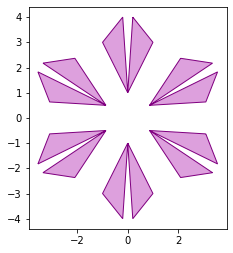

In [ ]:
import matplotlib.pyplot as plt
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale
from shapely.plotting import plot_polygon

d = Polygon([(0, 1), (1, 3), (0.2, 4)])
# your code

<details>
<summary>Lösung anzeigen (erst selbst probieren!)</summary>

```python
import matplotlib.pyplot as plt
import shapely
from shapely import Polygon
from shapely.affinity import rotate, scale
from shapely.plotting import plot_polygon

d = Polygon([(0, 1), (1, 3), (0.2, 4)])
paar = [d, scale(d, -1, 1, origin=(0, 0))]
teile = []
for w in range(0, 360, 60):
    for t in paar:
        teile.append(rotate(t, w, origin=(0, 0)))
muster = shapely.union_all(teile)
print(round(muster.area, 2))
fig, ax = plt.subplots(figsize=(4, 4))
plot_polygon(muster, ax=ax, facecolor='plum', edgecolor='purple', add_points=False)
ax.set_aspect('equal')
plt.show()
```

</details>

#### Aufgabe 7.5

Was wird ausgegeben? Überlege zuerst, was ausgegeben wird. Führe dann die Zelle aus und vergleiche.

In [ ]:
from shapely import Polygon
from shapely.affinity import rotate, scale, translate

q = Polygon([(0, 0), (1, 0), (1, 1), (0, 1)])
b = scale(translate(q, 1, 0), 2, 2, origin=(0, 0))
print(b.area, b.bounds)
print(round(rotate(b, 45, origin='centroid').area, 6))